# Thành viên 4 Phân loại và thống kê

**Đầu vào:** `features.csv` từ notebook 03 và file bàn giao các bước trước.
Phân loại bằng if/else, không dùng ML. Hai nhãn hình dạng/màu được giữ độc lập.
Notebook có thống kê, ảnh gán nhãn, xuất CSV, công cụ đối chiếu và kiểm thử hành vi.

In [1]:
from pathlib import Path
from dataclasses import dataclass
from types import SimpleNamespace
import os
import json
import hashlib
import math
import time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage.morphology import h_maxima
from skimage.feature import graycoprops
from IPython.display import display, Markdown

# Mặc định: đặt notebook cạnh raw_dataset và batch_dataset.
# Có thể đổi PROJECT_ROOT sang đường dẫn thư mục dữ liệu của bạn.
PROJECT_ROOT = Path(os.environ.get("RICE_DATA_ROOT", Path.cwd())).resolve()
OUTPUT_ROOT = Path(os.environ.get("RICE_OUTPUT_ROOT", PROJECT_ROOT / "outputs" / "notebook")).resolve()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"

In [2]:
SUPPORTED_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

def decode_image(data: bytes) -> np.ndarray:
    image = cv2.imdecode(np.frombuffer(data, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError('Không đọc được ảnh. Hãy dùng ảnh JPG, PNG, BMP hoặc TIFF hợp lệ.')
    return image

def read_image(path) -> np.ndarray:
    return decode_image(Path(path).read_bytes())

def write_image(path, image: np.ndarray) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    ok, encoded = cv2.imencode(path.suffix, image)
    if not ok:
        raise OSError(f'Không mã hóa được ảnh {path}')
    path.write_bytes(encoded.tobytes())

In [3]:
def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def load_stage1():
    folder = OUTPUT_ROOT / "01_du_lieu"
    path = folder / "manifest.csv"
    if not path.is_file():
        raise FileNotFoundError("Chưa có manifest.csv. Hãy chạy notebook 01 trước.")
    frame = pd.read_csv(path, keep_default_na=False)
    valid = frame[(frame["status"] == "ok") & (frame["duplicate_of"] == "")].copy()
    if valid.empty:
        raise ValueError("Không có ảnh hợp lệ duy nhất để xử lý.")
    return frame, valid, file_sha256(path)


def choose_demo(frame):
    matches = frame[frame["image_path"] == "raw_dataset/Tot/picT (1).png"]
    return (matches if len(matches) else frame).iloc[0]


def require_handoff(folder, expected_key, expected_value):
    path = Path(folder) / "handoff.json"
    if not path.is_file():
        raise FileNotFoundError(f"Chưa có {path.name} ở bước trước. Hãy chạy notebook theo thứ tự.")
    info = json.loads(path.read_text(encoding="utf-8"))
    if info.get(expected_key) != expected_value:
        raise ValueError("Dữ liệu bước trước đã thay đổi. Hãy chạy lại các notebook phía sau theo thứ tự.")
    return info

In [4]:
STAGE1 = OUTPUT_ROOT / "01_du_lieu"
STAGE2 = OUTPUT_ROOT / "02_phan_doan"
STAGE3 = OUTPUT_ROOT / "03_dac_trung"
STAGE4 = OUTPUT_ROOT / "04_phan_loai"
STAGE4.mkdir(parents=True, exist_ok=True)
manifest, valid_images, manifest_hash = load_stage1()
stage2_info = require_handoff(STAGE2, "stage1_manifest_sha256", manifest_hash)
stage3_info = require_handoff(STAGE3, "stage1_manifest_sha256", manifest_hash)
if stage3_info["stage2_handoff_sha256"] != file_sha256(STAGE2 / "handoff.json"):
    raise ValueError("Phân đoạn đã đổi. Hãy chạy lại notebook 03.")
if stage3_info["features_sha256"] != file_sha256(STAGE3 / "features.csv"):
    raise ValueError("features.csv đã bị sửa. Hãy chạy lại notebook 03.")
features = pd.read_csv(STAGE3 / "features.csv")
segmented_images = pd.read_csv(STAGE2 / "images.csv", keep_default_na=False)

## Đặt ngưỡng thử nghiệm

`length_ratio` = chiều dài hạt / chiều dài hạt nguyên tham chiếu, **không phải dài/rộng**.
Tham chiếu phải cùng giống và tỷ lệ chụp. Mặc định chưa có chuẩn nên hình dạng là Không xác định.
Có thể nhập chuẩn riêng cho từng `image_id`; không tự lấy trung bình của tất cả ảnh làm chuẩn.

| Quy tắc | Mặc định |
|---|---|
| Nguyên | length_ratio ≥ 0,80 |
| Vỡ | length_ratio < 0,70 |
| Hình dạng chưa xác định | Thiếu chuẩn, cắt biên hoặc nằm trong khoảng chuyển tiếp |
| Vàng | Tỷ lệ pixel vàng ≥ 0,25 |
| Sẫm | Tỷ lệ pixel sẫm ≥ 0,30 |
| Bình thường | Cả hai tỷ lệ ≤ 0,10 |

Nếu đồng thời đạt ngưỡng vàng và sẫm thì để Không xác định để kiểm tra.
Các ngưỡng này cần hiệu chỉnh từ nhãn chuẩn; không phải tiêu chuẩn thương mại.

In [5]:
DEFAULT_RULES = dict(reference_length_px=None, whole_min=0.80, broken_max=0.70,
                     yellow_min_fraction=0.25, dark_min_fraction=0.30,
                     normal_max_fraction=0.10, calibrated=False)

def validate_rules(rules):
    r = {**DEFAULT_RULES, **rules}
    if not 0 < r['broken_max'] < r['whole_min'] <= 1.5:
        raise ValueError('Cần 0 < broken_max < whole_min <= 1.5.')
    ref = r['reference_length_px']
    if ref is not None and (not math.isfinite(float(ref)) or float(ref) <= 0):
        raise ValueError('Chiều dài chuẩn phải là số dương, cùng tỷ lệ chụp với ảnh đang xét.')
    if not (0 <= r['normal_max_fraction'] < min(r['yellow_min_fraction'], r['dark_min_fraction']) <= 1):
        raise ValueError('Ngưỡng bình thường phải nhỏ hơn ngưỡng vàng/sẫm; các tỷ lệ nằm trong [0,1].')
    if max(r['yellow_min_fraction'], r['dark_min_fraction']) > 1:
        raise ValueError('Các tỷ lệ màu phải nằm trong [0,1].')
    return r

def classify_shape(features, rules):
    ref = rules.get('reference_length_px')
    if features.get('touches_border') or not features.get('feature_valid', True):
        return 'Không xác định', 'Hạt cắt biên hoặc đặc trưng hình học không hợp lệ.'
    if ref is None:
        return 'Không xác định', 'Chưa có chiều dài hạt nguyên tham chiếu cùng tỷ lệ chụp.'
    ratio = float(features['length']) / ref
    if ratio >= rules['whole_min']:
        return 'Nguyên', 'length/reference >= whole_min'
    elif ratio < rules['broken_max']:
        return 'Vỡ', 'length/reference < broken_max'
    return 'Không xác định', 'Tỷ lệ chiều dài nằm trong vùng chuyển tiếp.'

def classify_color(features, rules):
    if not features.get('feature_valid', True):
        return 'Không xác định', 'Đặc trưng không hợp lệ.'
    yellow, dark = features['yellow_fraction'], features['dark_fraction']
    if not all(math.isfinite(float(v)) for v in (yellow, dark)):
        return 'Không xác định', 'Thiếu đặc trưng màu.'
    if yellow >= rules['yellow_min_fraction'] and dark >= rules['dark_min_fraction']:
        return 'Không xác định', 'Đồng thời nhiều pixel vàng và sẫm; cần kiểm tra.'
    elif dark >= rules['dark_min_fraction']:
        return 'Sẫm', 'Tỷ lệ pixel sẫm đạt ngưỡng.'
    elif yellow >= rules['yellow_min_fraction']:
        return 'Vàng', 'Tỷ lệ pixel vàng đạt ngưỡng.'
    elif max(yellow, dark) <= rules['normal_max_fraction']:
        return 'Bình thường', 'Tỷ lệ pixel vàng và sẫm đều thấp.'
    return 'Không xác định', 'Tỷ lệ màu nằm trong vùng chuyển tiếp.'

def classify_grains(features, rules=None):
    rules = validate_rules(rules or {})
    result = features.copy()
    additions = []
    for _, row in result.iterrows():
        f = row.to_dict()
        if f['object_type'] == 'excluded_object':
            shape, sr, color, cr = 'Không áp dụng', f['exclusion_reason'], 'Không áp dụng', f['exclusion_reason']
            conclusion = 'Vùng bị loại'
        else:
            shape, sr = classify_shape(f, rules)
            color, cr = classify_color(f, rules)
            if shape == 'Vỡ' or color in {'Vàng', 'Sẫm'}:
                conclusion = 'Có dấu hiệu lỗi'
            elif shape == 'Nguyên' and color == 'Bình thường':
                conclusion = 'Đạt tiêu chí ảnh đã chọn'
            else:
                conclusion = 'Cần kiểm tra'
        additions.append(dict(length_ratio=f['length']/rules['reference_length_px'] if rules['reference_length_px'] else None,
                              shape_label=shape, color_label=color, shape_reason=sr, color_reason=cr,
                              conclusion=conclusion, rules_calibrated=rules['calibrated']))
    return pd.concat([result.reset_index(drop=True), pd.DataFrame(additions, columns=[
        'length_ratio', 'shape_label', 'color_label', 'shape_reason', 'color_reason', 'conclusion', 'rules_calibrated'])], axis=1)

In [6]:
REFERENCE_LENGTH_BY_IMAGE = {
    # "image_id_trong_features_csv": chieu_dai_chuan_px_anh_goc,
}
RULES = validate_rules(dict(reference_length_px=None, whole_min=0.80, broken_max=0.70,
                            yellow_min_fraction=0.25, dark_min_fraction=0.30,
                            normal_max_fraction=0.10, calibrated=False))
# Giữ False khi chưa có ít nhất 5 hạt nguyên gán nhãn ở ảnh calibration.
USE_VERIFIED_CALIBRATION_LABELS = False
MANUAL_LABELS_PATH = STAGE4 / "manual_labels.csv"

## Tạo mẫu nhãn đối chiếu và khảo sát dữ liệu hiệu chỉnh

File mẫu để trống nhãn và `verified=False`. Sao chép thành `manual_labels.csv` rồi tự điền:
image_id, hộp bao, shape_label, color_label, reviewer, verified.
Thêm hạt thuật toán bỏ sót, xóa vật không phải hạt và sửa hộp bao bị gộp.
Chỉ dùng ảnh calibration để đặt chuẩn/ngưỡng; các ảnh test giữ riêng để đánh giá.
Không lấy nhãn dự đoán làm nhãn chuẩn.

In [7]:
template = features[["image_id", "image_path", "grain_id", "bbox_x", "bbox_y", "bbox_w", "bbox_h", "split"]].copy()
for col in ["shape_label", "color_label", "reviewer", "notes"]:
    template[col] = ""
template["verified"] = False
template_path = STAGE4 / "manual_labels_template.csv"
if not template_path.exists():
    template.to_csv(template_path, index=False, encoding="utf-8-sig")
else:
    print("Giữ nguyên mẫu nhãn đã có. Nếu đổi phân đoạn, hãy dùng thư mục đầu ra mới.")

def estimate_image_reference(truth, image_features):
    verified = truth.verified.astype(str).str.lower().isin(["true", "1"])
    selected = truth[verified & (truth.shape_label == "Nguyên")].copy()
    if selected.reviewer.fillna("").str.strip().eq("").any():
        raise ValueError("Nhãn kiểm chứng cần tên người gán nhãn.")
    candidates = image_features[(image_features.object_type == "candidate_grain") & ~image_features.touches_border.astype(bool)]
    if len(selected) < 5 or len(candidates) < 5:
        raise ValueError("Cần ít nhất 5 hạt nguyên đã kiểm chứng, không cắt biên.")
    matrix = np.array([[box_iou(a, b) for b in candidates[BOX].to_numpy()] for a in selected[BOX].to_numpy()])
    aa, bb = linear_sum_assignment(-((matrix >= .5) * (min(matrix.shape)+1) + matrix))
    matched = [candidates.iloc[b] for a, b in zip(aa, bb) if matrix[a, b] >= .5]
    if len(matched) < 5:
        raise ValueError("Chưa khớp đủ 5 hạt nguyên với đặc trưng.")
    return float(np.median([r.length for r in matched]))

## Hàm đối chiếu hộp bao và nhãn

Khớp một-một bằng IoU hộp bao ≥ 0,5. Độ chính xác nhãn chỉ tính trên hạt khớp.
Chỉ báo precision/recall phát hiện và sai số đếm khi đã xác nhận gán nhãn hết một ảnh.
IoU hộp bao không phải IoU đường biên/mask.

In [8]:
BOX=['bbox_x','bbox_y','bbox_w','bbox_h']

def box_iou(a,b):
    ax,ay,aw,ah=map(float,a)
    bx,by,bw,bh=map(float,b)
    inter=max(0,min(ax+aw,bx+bw)-max(ax,bx))*max(0,min(ay+ah,by+bh)-max(ay,by))
    union=aw*ah+bw*bh-inter
    return inter/union if union>0 else 0.0

def evaluate_predictions(truth,predicted,complete_image=False,min_iou=.5):
    required=set(BOX+['verified','reviewer','shape_label','color_label'])
    if not required.issubset(truth.columns):
        raise ValueError(f'Nhãn cần các cột {sorted(required)}')
    verified=truth.verified.astype(str).str.lower().isin(['true','1'])
    if not verified.any():
        raise ValueError('Chưa có nhãn kiểm chứng. Không thể tính độ chính xác từ nhãn tự sinh.')
    if complete_image and not verified.all():
        raise ValueError('Đánh giá phát hiện toàn ảnh yêu cầu kiểm chứng mọi dòng nhãn.')
    gt=truth[verified].reset_index(drop=True)
    if gt.reviewer.fillna('').str.strip().eq('').any():
        raise ValueError('Mỗi nhãn kiểm chứng cần tên người gán nhãn ở cột reviewer.')
    if not gt.shape_label.isin(['Nguyên','Vỡ','Không xác định']).all() or not gt.color_label.isin(['Bình thường','Vàng','Sẫm','Không xác định']).all():
        raise ValueError('Nhãn kiểm chứng thiếu hoặc sai tên nhãn hình dạng/màu sắc.')
    if gt[BOX].isna().any().any() or (gt[['bbox_w','bbox_h']]<=0).any().any():
        raise ValueError('Hộp bao nhãn chuẩn phải hợp lệ và có kích thước dương.')
    pred=predicted[predicted.object_type=='candidate_grain'].reset_index(drop=True)
    matrix=np.array([[box_iou(a,b) for b in pred[BOX].to_numpy()] for a in gt[BOX].to_numpy()]).reshape(len(gt),len(pred))
    score=(matrix>=min_iou).astype(float)*1000+matrix
    pairs=[]
    if len(gt) and len(pred):
        aa,bb=linear_sum_assignment(-score)
        pairs=[(a,b) for a,b in zip(aa,bb) if matrix[a,b]>=min_iou]
    report=dict(verified_truth_grains=len(gt),predicted_grains=len(pred),matched_grains=len(pairs),min_box_iou=min_iou,
                complete_image=bool(complete_image),mean_matched_box_iou=float(np.mean([matrix[a,b] for a,b in pairs])) if pairs else None,
                classification_scope='Độ chính xác chỉ trên hạt đã khớp hộp bao, không bao gồm hạt bỏ sót.')
    confusion={}
    for axis in ['shape_label','color_label']:
        records=[{'truth':gt.iloc[a][axis],'prediction':pred.iloc[b][axis]} for a,b in pairs]
        report[f'{axis}_accuracy']=sum(r['truth']==r['prediction'] for r in records)/len(records) if records else None
        confusion[axis]=pd.crosstab(pd.Series([r['truth'] for r in records],name='truth'),pd.Series([r['prediction'] for r in records],name='prediction')).to_dict()
    if complete_image:
        tp=len(pairs)
        report.update(detection_precision=tp/len(pred) if len(pred) else 0.0,detection_recall=tp/len(gt),
                      missed_grains=len(gt)-tp,extra_regions=len(pred)-tp,count_absolute_error=abs(len(gt)-len(pred)))
    else:
        report['detection_note']='Chưa xác nhận gán nhãn hết ảnh; không tính precision/recall và sai số đếm.'
    report['confusion']=confusion
    return report

In [9]:
if USE_VERIFIED_CALIBRATION_LABELS:
    if not MANUAL_LABELS_PATH.is_file():
        raise FileNotFoundError("Chưa có manual_labels.csv đã gán nhãn.")
    manual = pd.read_csv(MANUAL_LABELS_PATH)
    for image_id, group in manual.groupby("image_id"):
        image_features = features[features.image_id == image_id]
        if image_features.empty:
            raise ValueError(f"Không có ảnh {image_id} trong đặc trưng hiện tại.")
        if not image_features.split.eq("calibration").all():
            print("Bỏ qua ảnh test khi đặt chuẩn:", image_id)
            continue
        REFERENCE_LENGTH_BY_IMAGE[image_id] = estimate_image_reference(group, image_features)
    print("Tham chiếu riêng từng ảnh calibration:", REFERENCE_LENGTH_BY_IMAGE)
else:
    print("Chưa dùng nhãn thủ công để đặt chuẩn; sử dụng cấu hình đã nhập.")

Chưa dùng nhãn thủ công để đặt chuẩn; sử dụng cấu hình đã nhập.


## Phân loại theo từng ảnh

In [10]:
classified_parts = []
for row in valid_images.itertuples(index=False):
    image_features = features[features.image_id == row.image_id].copy()
    rules = {**RULES, "reference_length_px": REFERENCE_LENGTH_BY_IMAGE.get(row.image_id)}
    classified_parts.append(classify_grains(image_features, rules))
classified = pd.concat(classified_parts, ignore_index=True)
classified.to_csv(STAGE4 / "classification.csv", index=False, encoding="utf-8-sig")
(STAGE4 / "rules.json").write_text(json.dumps(dict(rules=RULES, reference_length_by_image=REFERENCE_LENGTH_BY_IMAGE), ensure_ascii=False, indent=2), encoding="utf-8")
display(classified[["image_path", "grain_id", "length", "length_ratio", "shape_label", "color_label", "conclusion"]].head(20))
if not REFERENCE_LENGTH_BY_IMAGE:
    print("Lưu ý: chưa có chiều dài chuẩn nên hình dạng của ảnh thật để Không xác định.")
print("Các ngưỡng vẫn là thử nghiệm; chưa có độ chính xác ảnh thật khi thiếu nhãn kiểm chứng.")

,image_path,grain_id,length,length_ratio,shape_label,color_label,conclusion
0,batch_dataset/picCacloaigao (1).jpg,1,140.903717,None,Không xác định,Vàng,Có dấu hiệu lỗi
1,batch_dataset/picCacloaigao (1).jpg,2,126.320274,None,Không xác định,Vàng,Có dấu hiệu lỗi
2,batch_dataset/picCacloaigao (1).jpg,3,159.671677,None,Không xác định,Vàng,Có dấu hiệu lỗi
3,batch_dataset/picCacloaigao (1).jpg,4,129.938461,None,Không xác định,Bình thường,Cần kiểm tra
4,batch_dataset/picCacloaigao (1).jpg,5,116.599213,None,Không xác định,Vàng,Có dấu hiệu lỗi
5,batch_dataset/picCacloaigao (1).jpg,6,116.632492,None,Không xác định,Bình thường,Cần kiểm tra
6,batch_dataset/picCacloaigao (1).jpg,7,54.321842,None,Không xác định,Bình thường,Cần kiểm tra
7,batch_dataset/picCacloaigao (1).jpg,8,71.072609,None,Không xác định,Bình thường,Cần kiểm tra
8,batch_dataset/picCacloaigao (1).jpg,9,144.290192,None,Không xác định,Bình thường,Cần kiểm tra
9,batch_dataset/picCacloaigao (1).jpg,10,119.223724,None,Không xác định,Vàng,Có dấu hiệu lỗi


Lưu ý: chưa có chiều dài chuẩn nên hình dạng của ảnh thật để Không xác định.
Các ngưỡng vẫn là thử nghiệm; chưa có độ chính xác ảnh thật khi thiếu nhãn kiểm chứng.


## Thống kê và biểu đồ

In [11]:
def summarize_results(frame):
    grains = frame[frame.object_type == 'candidate_grain']
    n = len(grains)
    rows = []
    for axis, column, labels in [('Hình dạng', 'shape_label', ['Nguyên', 'Vỡ', 'Không xác định']),
                                  ('Màu sắc', 'color_label', ['Bình thường', 'Vàng', 'Sẫm', 'Không xác định'])]:
        for label in labels:
            count = int((grains[column] == label).sum())
            rows.append(dict(group=axis, label=label, count=count, percentage=100*count/n if n else 0.0))
    unknown = int(((grains.shape_label == 'Không xác định') | (grains.color_label == 'Không xác định')).sum())
    def mean(col):
        value = grains[col].mean()
        return None if pd.isna(value) else float(value)
    summary = dict(detected_regions=len(frame), total_grains=n, excluded_objects=len(frame)-n,
                   unknown_grains=unknown, mean_area_px2=mean('area'), mean_length_px=mean('length'),
                   mean_h=mean('mean_h'), mean_s=mean('mean_s'), mean_v=mean('mean_v'),
                   border_grains=int(grains.touches_border.sum()),
                   scope='Đánh giá hình dạng và màu sắc quan sát được; ngưỡng cần hiệu chỉnh bằng nhãn chuẩn.')
    return summary, pd.DataFrame(rows)

def create_statistics_figure(distribution):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    for ax, group in zip(axes, ['Hình dạng', 'Màu sắc']):
        subset = distribution[distribution.group == group]
        bars = ax.bar(subset.label, subset['count'], color=['#3b8069', '#d6a348', '#7b89a1', '#815b72'][:len(subset)])
        ax.set_title(group)
        ax.set_ylabel('Số hạt')
        ax.tick_params(axis='x', labelsize=9)
        ax.bar_label(bars, labels=[f'{r.count}\n({r.percentage:.1f}%)' for r in subset.itertuples()], padding=3)
        ax.set_ylim(0, max(1, subset['count'].max())*1.3)
    return fig

,detected_regions,total_grains,excluded_objects,unknown_grains,mean_area_px2,mean_length_px,mean_h,mean_s,mean_v,border_grains
0,14415,14386,29,14386,8121.864078,133.361866,22.688212,66.757372,122.231596,37


,group,label,count,percentage
0,Hình dạng,Nguyên,0,0.000000
1,Hình dạng,Vỡ,0,0.000000
2,Hình dạng,Không xác định,14386,100.000000
3,Màu sắc,Bình thường,2873,19.970805
4,Màu sắc,Vàng,8882,61.740581
5,Màu sắc,Sẫm,443,3.079383
6,Màu sắc,Không xác định,2188,15.209231


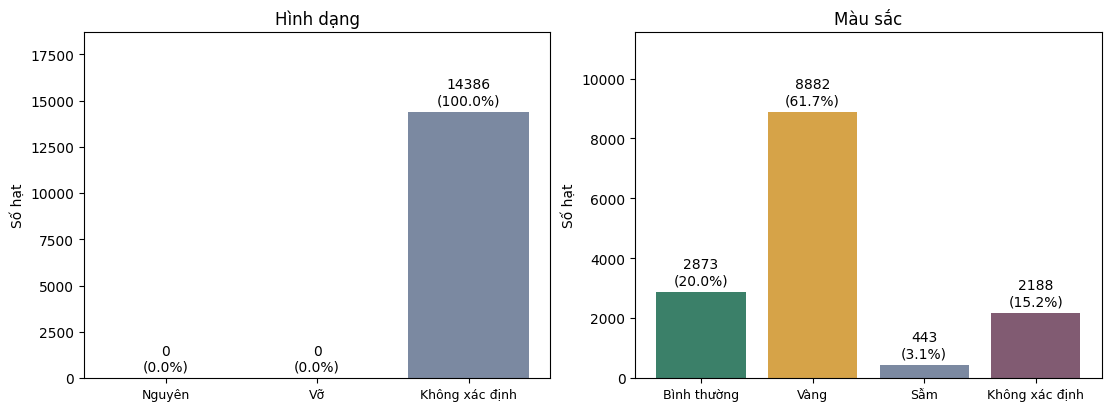

In [12]:
total_summary, distribution = summarize_results(classified)
per_image = []
for row in valid_images.itertuples(index=False):
    summary, _ = summarize_results(classified[classified.image_id == row.image_id])
    per_image.append(dict(image_id=row.image_id, image_path=row.image_path, split=row.split, **summary))
per_image_summary = pd.DataFrame(per_image)
distribution.to_csv(STAGE4 / "statistics.csv", index=False, encoding="utf-8-sig")
per_image_summary.to_csv(STAGE4 / "per_image_summary.csv", index=False, encoding="utf-8-sig")
(STAGE4 / "summary.json").write_text(json.dumps(total_summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame([total_summary]).drop(columns="scope"))
display(distribution)
fig = create_statistics_figure(distribution)
fig.savefig(STAGE4 / "statistics.png", dpi=140)
plt.show()

## Ảnh đánh số và nhãn minh họa

N = Nguyên; V = Vỡ; BT = Bình thường; Y = Vàng; S = Sẫm; ? = Không xác định; X = vùng bị loại.
Tỷ lệ thống kê tính riêng cho hình dạng và màu sắc; không cộng hai trục với nhau.

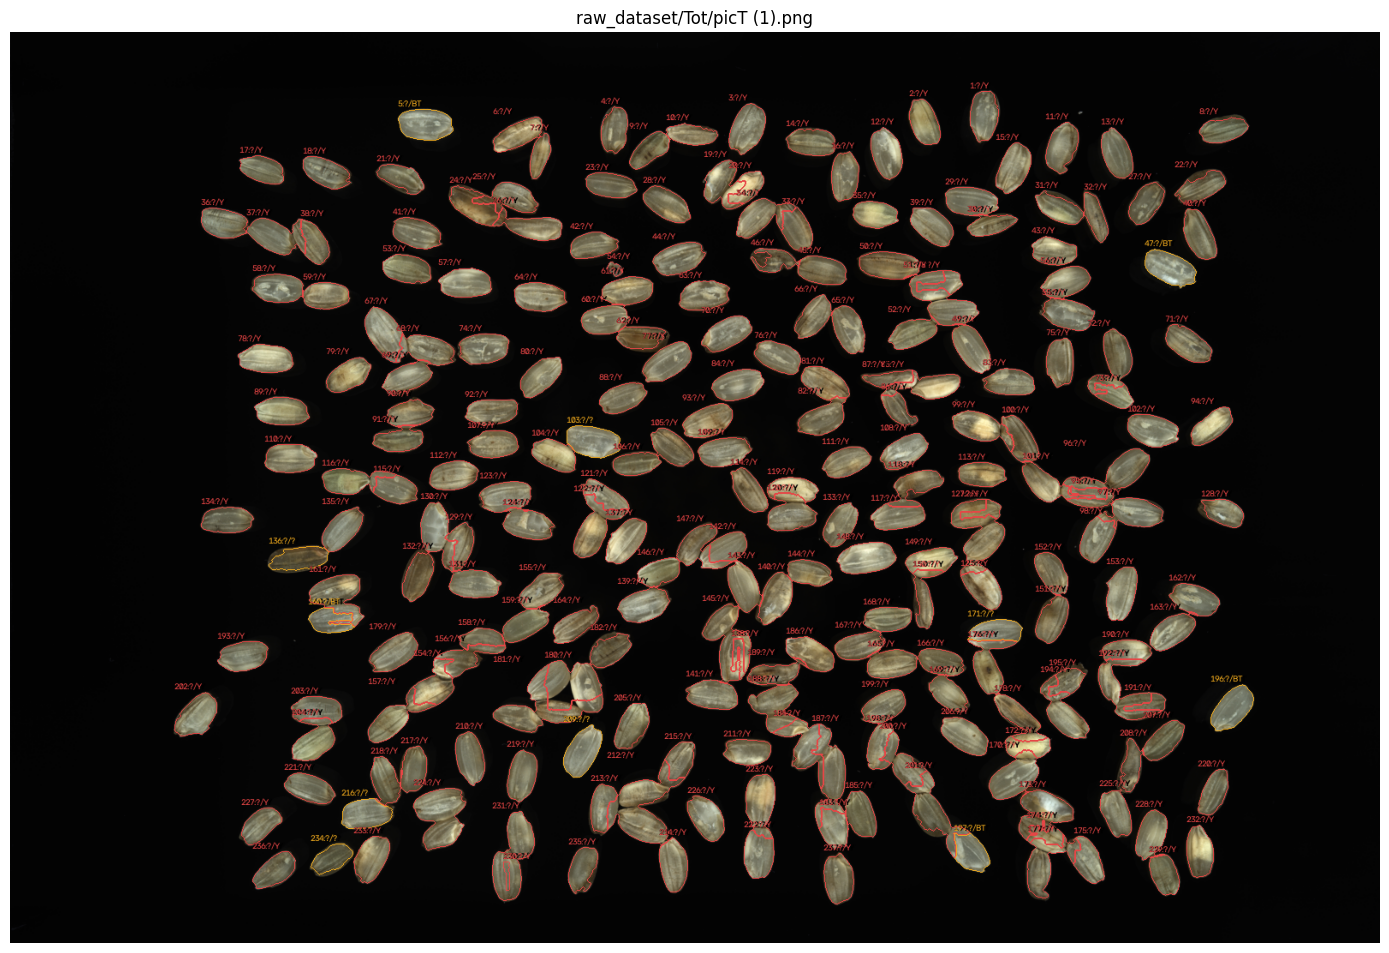

In [13]:
demo = choose_demo(valid_images)
info = segmented_images[segmented_images.image_id == demo.image_id].iloc[0]
overlay = read_image(STAGE1 / demo.color_path)
with np.load(STAGE2 / info.instance_path, allow_pickle=False) as stored:
    labels = stored["labels"]
sample = classified[classified.image_id == demo.image_id]
sx, sy = float(demo.scale_x), float(demo.scale_y)
for row in sample.itertuples(index=False):
    x, y = int(round(row.bbox_x*sx)), int(round(row.bbox_y*sy))
    w, h = int(round(row.bbox_w*sx)), int(round(row.bbox_h*sy))
    mask = (labels[y:y+h, x:x+w] == row.grain_id).astype(np.uint8)*255
    cc, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cc = [c + np.array([[[x, y]]], np.int32) for c in cc]
    if row.object_type == "excluded_object":
        color, label = (150,150,150), f"{row.grain_id}:X"
    else:
        shape = {"Nguyên":"N", "Vỡ":"V", "Không xác định":"?"}[row.shape_label]
        hue = {"Bình thường":"BT", "Vàng":"Y", "Sẫm":"S", "Không xác định":"?"}[row.color_label]
        label = f"{row.grain_id}:{shape}/{hue}"
        color = (70,190,90) if row.conclusion == "Đạt tiêu chí ảnh đã chọn" else (30,170,240)
        if row.conclusion == "Có dấu hiệu lỗi":
            color = (70,70,230)
    cv2.drawContours(overlay, cc, -1, color, 1)
    cv2.putText(overlay, label, (x, max(10,y-3)), cv2.FONT_HERSHEY_SIMPLEX, .32, (0,0,0), 2, cv2.LINE_AA)
    cv2.putText(overlay, label, (x, max(10,y-3)), cv2.FONT_HERSHEY_SIMPLEX, .32, color, 1, cv2.LINE_AA)
write_image(STAGE4 / "sample_classified.png", overlay)
plt.figure(figsize=(14, 10))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title(demo.image_path)
plt.axis("off")
plt.tight_layout()
plt.show()

## Đối chiếu nhãn thủ công nếu đã có

Sau khi gán nhãn, đặt `MANUAL_LABELS_PATH` trỏ tới file của bạn và chạy lại notebook 04.
`COMPLETE_IMAGE_IDS` chỉ chứa ảnh đã gán nhãn **mọi hạt**, kể cả hạt bị bỏ sót.
Để trống khi chưa chắc; khi đó không tính precision/recall phát hiện hoặc sai số đếm toàn ảnh.

In [14]:
COMPLETE_IMAGE_IDS = set()
evaluation_reports = []
if MANUAL_LABELS_PATH.is_file():
    manual = pd.read_csv(MANUAL_LABELS_PATH)
    if "image_id" not in manual:
        raise ValueError("Nhãn thủ công cần cột image_id.")
    for image_id, truth in manual.groupby("image_id"):
        if not truth.verified.astype(str).str.lower().isin(["true", "1"]).any():
            continue
        predictions = classified[classified.image_id == image_id]
        report = evaluate_predictions(truth, predictions, complete_image=image_id in COMPLETE_IMAGE_IDS)
        evaluation_reports.append(dict(image_id=image_id, **report))
    if evaluation_reports:
        (STAGE4 / "evaluation.json").write_text(json.dumps(evaluation_reports, ensure_ascii=False, indent=2), encoding="utf-8")
        display(pd.DataFrame([{k:v for k,v in r.items() if k != "confusion"} for r in evaluation_reports]))
    else:
        print("File nhãn chưa có dòng kiểm chứng; chưa tính độ chính xác ảnh thật.")
else:
    print("Chưa có manual_labels.csv; chỉ xuất mẫu nhãn, không báo độ chính xác ảnh thật.")

Chưa có manual_labels.csv; chỉ xuất mẫu nhãn, không báo độ chính xác ảnh thật.


## Kiểm tra hành vi và tổng kết bàn giao

Các kiểm tra sau dùng vector đặc trưng và ảnh giả lập nhỏ, chỉ xác nhận cách hoạt động của if/else.
Sản phẩm cuối: classification.csv, statistics.csv, per_image_summary.csv, summary.json,
rules.json, biểu đồ, ảnh minh họa và mẫu nhãn thủ công trong `04_phan_loai/`.

Chạy lại notebook 01 → phải chạy lại 02 → 03 → 04 nếu dữ liệu/cấu hình thay đổi.
Chỉ đổi quy tắc phân loại → chạy lại 04. Đổi ngưỡng pixel màu hoặc GLCM → chạy lại 03–04.

In [15]:
test_rules = validate_rules({"reference_length_px":100})
f = dict(length=80, feature_valid=True, touches_border=False)
assert classify_shape(f, test_rules)[0] == "Nguyên"
assert classify_shape({**f, "length":69}, test_rules)[0] == "Vỡ"
assert classify_shape({**f, "length":70}, test_rules)[0] == "Không xác định"
assert classify_shape({**f, "touches_border":True}, test_rules)[0] == "Không xác định"
assert classify_color(dict(feature_valid=True,yellow_fraction=.3,dark_fraction=.4), test_rules)[0] == "Không xác định"
assert len(classified) == len(features)
for _, group in distribution.groupby("group"):
    assert abs(group.percentage.sum() - (100 if total_summary["total_grains"] else 0)) < 1e-6
assert total_summary["total_grains"] + total_summary["excluded_objects"] == len(features)
print("Đạt: biên ngưỡng, nhãn chưa xác định, số dòng và tỷ lệ thống kê nhất quán.")
print("Hoàn thành chuỗi 4 notebook. Chưa kết luận độ chính xác ảnh thật khi thiếu nhãn chuẩn.")

Đạt: biên ngưỡng, nhãn chưa xác định, số dòng và tỷ lệ thống kê nhất quán.
Hoàn thành chuỗi 4 notebook. Chưa kết luận độ chính xác ảnh thật khi thiếu nhãn chuẩn.
